# Kalman Filter Altitude and Vertical Velocity Estimation

We implement a linear, 2-state Kalman filter to estimate altitude and vertical velocity. The accelerometer predicts how altitude (h) and vertical velocity (v) change with each timestep, and the barometer corrects the altitude. We use the noise levels measured in the naive estimation notebook. Press `shift + enter` to run each cell.

In [1]:
import numpy as np

import utils

## Settings

In [2]:
# Recordings (folders containing acc_baro.csv and meta.json)
STAIRS_UP_PATH = "recordings/stairs_up"
STAIRS_DOWN_PATH = "recordings/stairs_down"
STAIRS_ROUND_PATH = "recordings/stairs_round"
LIFT_PATH = "recordings/lift"

# Time to measure barometer and accelerometer reference points
REF_TIME_S = 2.0

# Noise std devs measured from the static recording (naive estimation notebook)
SIGMA_A = 0.0212 # accelerometer
SIGMA_Z = 0.0255 # barometer (position sensor)

## Kalman Filter

The state vector has two elements (position and velocity: $x = [p, v]^\mathsf{T}$). The accelerometer is the input $u$, and the barometer is the measurement $z$. The system is described by:

* Motion model: $x_k = F x_{k-1} + B u + w$, where $w$ is process noise
* Measurement model: $z = H x + D u + \nu$, where $\nu$ is measurement noise (not velocity $v$)

The linear Kalman filter equations we use rely on these assumptions:

* The motion and measurement models are linear
* Process noise is zero-mean, white, Gaussian, with known covariance $Q$
* Measurement noise is zero-mean, white, Gaussian, with known covariance $R$
* Process and measurement noise are independent (separate sensors)

### Predict

On each accelerometer sample, predict the new state using constant-acceleration kinematics.

#### Calculate the system matrices

If your system has a constant $\Delta t$, these are constant values. If the time between sensor measurements varies, then we need to recompute them each time.

State transition matrix: $F = \begin{bmatrix} 1 & \Delta t \\ 0 & 1 \end{bmatrix}$

Input/control matrix: $B = \begin{bmatrix} \tfrac{1}{2}\Delta t^2 \\ \Delta t \end{bmatrix}$

Measurement matrix: $H = \begin{bmatrix} 1 & 0 \end{bmatrix}$

Feedthrough matrix: $D = 0$

#### Calculate the noise covariance matrices

Process noise covariance (depends on $\Delta t$): $Q = B B^\mathsf{T} \sigma_a^2$

Measurement noise covariance (constant): $R = \sigma_z^2$

#### Perform the prediction steps

**1a)** Predict the state (prior): $\hat{x}^- = F \hat{x} + B u$

**1b)** Predict the error covariance: $P^- = F P F^\mathsf{T} + Q$

**1c)** Predict the measurement: $\hat{z} = H \hat{x}^- + D u$

> Note: we'll run step 1c inside the correct step, as it's only needed when a barometer sample arrives.

### Correct

On each barometer sample, blend the step 1 prediction with the barometer measurement, weighted by the Kalman gain $K$.

#### Calculate the innovation values

Compute the innovation (how far off the prediction was): $y = z - \hat{z}$

Compute the innovation covariance (how far off we expect it to be): $S = H P^- H^\mathsf{T} + R$

#### Perform the correction steps

**2a)** Compute the Kalman gain: $K = P^- H^\mathsf{T} S^{-1}$

**2b)** Update the state estimate (posterior): $\hat{x} = \hat{x}^- + K y$

**2c)** Update the error covariance: $P = (I - K H) P^-$

In [3]:
class KalmanFilterPosVel:
    """
    Linear Kalman filter for 1D motion. We estimate a two-element state,
    x = [p, v], where p is position (e.g. distance, height) and v is velocity.
    The input (u) is measured acceleration, and the measurement (z) is
    position.
    """

    def __init__(
        self,
        sigma_a,
        sigma_z,
        p0=0.0,
        v0=0.0,
        sigma_p0=0.01,
        sigma_v0=0.01,
    ):
        """
        Constructor: set initial values.

        Args:
            sigma_a: acceleration (input) noise std dev (m/s²)
            sigma_z: position sensor (measurement) noise std dev (m)
            p0: initial position (m)
            v0: initial velocity (m/s)
            sigma_p0: initial position uncertainty, std dev (m)
            sigma_v0: initial velocity uncertainty, std dev (m/s)
        """
        # Store acceleration noise (Q is rebuilt each step from dt)
        self.sigma_a = sigma_a

        # Constant matrices
        self.H = np.array([[1.0, 0.0]])
        self.D = np.array([[0.0]])
        self.R = np.array([[sigma_z**2]])

        # Initial state (x) and covariance (P) estimates
        self.x = np.array([p0, v0])
        self.P = np.diag([sigma_p0**2, sigma_v0**2])

        # Initialize acceleration (none yet)
        self.u = 0.0

        # No timestamp of last predict step
        self.t_prev = None

    def predict(self, t, a):
        """
        Predict the state at time t, using the acceleration from the previous
        step.

        Args:
            t: timestamp (s)
            a: acceleration (m/s²)
        """
        # Skip the prediction on the first timestep (no dt)
        if self.t_prev is not None:
            # Compute system and process noise matrices depending on dt
            dt = t - self.t_prev
            F = np.array([[1.0, dt], [0.0, 1.0]])
            B = np.array([0.5 * dt**2, dt])
            Q = np.outer(B, B) * self.sigma_a**2

            # 1a) predict state
            self.x = F @ self.x + B * self.u

            # 1b) predict covariance
            self.P = F @ self.P @ F.T + Q

        # Hold the acceleration as the input for the next timestep
        self.u = a

        # Update previous timestamp
        self.t_prev = t

        return self.x

    def correct(self, z):
        """
        Correct the prior estimate using the position sensor’s measurement.

        Args:
            z: position sensor's reading (m)
        """
        # 1c) predict position measurement
        z_hat = self.H @ self.x + self.D @ np.array([self.u])
        
        # Innovation (how far off the prediction was)
        y = z - z_hat

        # Innovation covariance (spread of the innovation term)
        S = self.H @ self.P @ self.H.T + self.R

        # 2a) Kalman gain
        K = self.P @ self.H.T @ np.linalg.inv(S)

        # 2b) update the estimated state
        self.x = self.x + K @ y

        # 2c) update the error covariance
        self.P = (np.eye(2) - K @ self.H) @ self.P

        return self.x

## Helper Functions

In [4]:
def run_kalman_filter(events, sigma_a, sigma_z):
    """
    Run the Kalman filter over the provided sorted events.
    """
    # Construct the filter: assume initial pos/vel are 0, pos std dev is
    # barometer std dev, and vel std dev is ~5 cm/s (little movement at rest)
    kf = KalmanFilterPosVel(
        sigma_a,
        sigma_z,
        p0=0.0,
        v0=0.0,
        sigma_p0=sigma_z,
        sigma_v0=0.05,
    )

    # Run through each event, calling predict or correct as needed
    ts = []
    ps = []
    vs = []
    for t, name, value in events:
        if name == "acc":
            x = kf.predict(t, value)
        else:
            x = kf.correct(value)
        ts.append(t)
        ps.append(x[0])
        vs.append(x[1])

    return np.array(ts), np.array(ps), np.array(vs)

In [5]:
def centered_maf(x, n):
    """
    Centered moving average filter over n samples. Only use samples that exist.
    """
    kernel = np.ones(n)
    
    # Sum in each window
    total = np.convolve(x, kernel, mode="same")

    # Only count samples that exist
    count = np.convolve(np.ones(len(x)), kernel, mode="same")
    
    return total / count

In [6]:
def load_and_sort_events(path, ref_time):
    """
    Load recording, generate reference (zero points) from gravity and current
    barometric pressure at the start, and sort the relative acc/baro readings
    by timestamp order. In addition, generate reference altitude/velocity logs
    by smoothing out and differentiating the barometer readings.
    """

    # Load the recording
    rec, rec_meta = utils.load_recording(path)
    t_acc = rec["t"]
    az = rec["az"]
    
    # Read barometer measurements (they are recorded at ~50Hz)
    t_baro, baro = utils.baro_samples(rec)
    
    # Print summary
    print(f"Duration: {t_acc[-1]:.1f} s")
    print(f"Accel samples: {len(t_acc)} ({(len(t_acc) - 1) / (t_acc[-1] - t_acc[0]):.1f} Hz)")
    print(f"Baro samples: {len(t_baro)} ({(len(t_baro) - 1) / (t_baro[-1] - t_baro[0]):.1f} Hz)")
    
    # Altitude reference (zero point): average of the first few seconds
    baro_ref = np.mean(baro[t_baro < t_baro[0] + ref_time])
    baro_rel = baro - baro_ref
    
    # Acceleration reference (gravity + bias): average of the first few seconds
    g_ref = np.mean(az[t_acc < t_acc[0] + ref_time])
    az_rel = az - g_ref
    
    # Sort acc and baro samples into a single, sorted (by time) list
    events = utils.sorted_streams(
        ("acc", t_acc, az_rel),
        ("baro", t_baro, baro_rel),
    )

    # Position reference: smooth the barometer over ~1 sec with centered MAF
    n = int(1.0 * (len(t_baro) - 1) / (t_baro[-1] - t_baro[0]))
    p_ref = centered_maf(baro_rel, n)
    
    # Velocity reference: differentiate smoothed barometer log
    v_ref = np.gradient(p_ref, t_baro)

    return {
        "events": events,
        "t_acc": t_acc,
        "az_rel": az_rel,
        "t_baro": t_baro,
        "baro_rel": baro_rel,
        "p_ref": p_ref,
        "v_ref": v_ref,
    }

In [7]:
def rms(x):
    """Root mean square"""
    return np.sqrt(np.mean(x**2))

In [8]:
def integrate_acc(t, a):
    """
    Integrate accelerometer once to get velocity and again to get position.
    Used for comparison against the Kalman filter output.
    """
    v = np.zeros(len(a))
    h = np.zeros(len(a))
    for k in range(1, len(a)):
        dt = t[k] - t[k - 1]
        v[k] = v[k - 1] + a[k - 1] * dt
        h[k] = h[k - 1] + v[k - 1] * dt + 0.5 * a[k - 1] * dt**2

    return v, h

In [9]:
def eval_log(path, ref_time, sigma_a, sigma_z):
    # Load log
    data = load_and_sort_events(path, ref_time)
    
    # Perform naive estimation from accelerometer
    v_acc, p_acc = integrate_acc(data["t_acc"], data["az_rel"])
    
    # Run filter on sorted events
    t_kf, p_kf, v_kf = run_kalman_filter(data["events"], sigma_a, sigma_z)
    
    # Compute RMS error of velocity estimate vs. reference
    v_kf_at_baro = np.interp(data["t_baro"], t_kf, v_kf)
    v_err_rms = rms(v_kf_at_baro - data["v_ref"])
    print(f"v_err RMS={v_err_rms:.3f} m/s")
    
    # Add references to each trace
    p_traces = [
        (data["t_baro"], data["baro_rel"], "baro", {"color": "orange"}),
        (data["t_acc"], p_acc, "acc", {"color": "blue"}),
        (t_kf, p_kf, "KF x[0]", {"color": "red"}),
        (data["t_baro"], data["p_ref"], "smoothed baro", {"color": "k", "ls": ":", "lw": 2}),
    ]
    v_traces = [
        (data["t_acc"], v_acc, "acc", {"color": "blue"}),
        (t_kf, v_kf, "KF x[1]", {"color": "red"}),
        (data["t_baro"], data["v_ref"], "diff baro", {"color": "k", "ls": "--", "lw": 1}),
    ]
    
    # Plot position (altitude) and velocity vs references
    utils.plot_traces(p_traces, "Altitude (m)", title=f"KF estimation vs. naive vs. reference")
    utils.plot_traces(v_traces, "Velocity (m/s)", title=f"KF estimation vs. naive vs. reference")

## Tuning: Sweep sigma_a

We measured `sigma_a` with the accelerometer at rest. Walking and small tilts add errors that this value did not include, which means the filter may trust the accelerometer too much. Increasing `sigma_a` tells the filter to trust the accelerometer less and the barometer more.

As a result, we test the KF on the `stairs_up` recording a few times with different `sigma_a` values and pick the one that looks the best.

In [10]:
# Load the recording, subtract out the zero points, sort the events
data = load_and_sort_events(STAIRS_UP_PATH, REF_TIME_S)

Duration: 20.0 s
Accel samples: 2491 (124.5 Hz)
Baro samples: 998 (49.9 Hz)


sigma_a=0.0212, v_err RMS=0.052 m/s
sigma_a=0.1000, v_err RMS=0.050 m/s
sigma_a=0.5000, v_err RMS=0.049 m/s
sigma_a=1.0000, v_err RMS=0.052 m/s
sigma_a=5.0000, v_err RMS=0.099 m/s


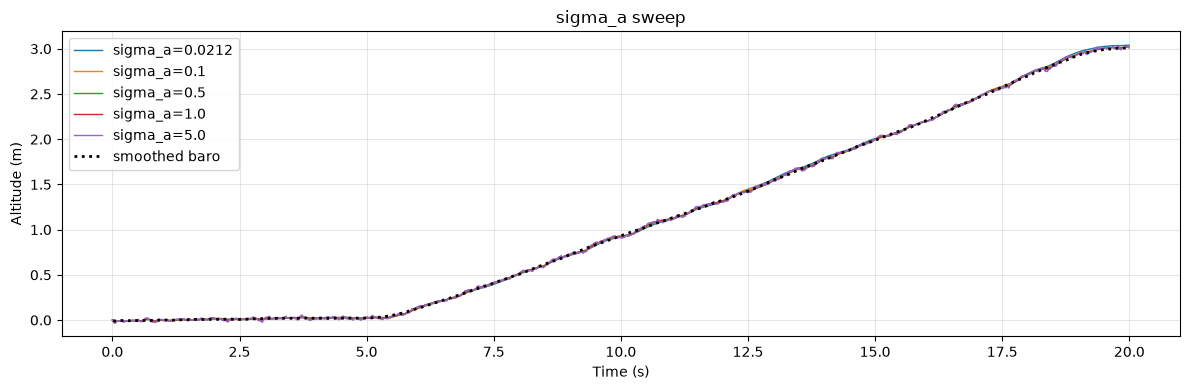

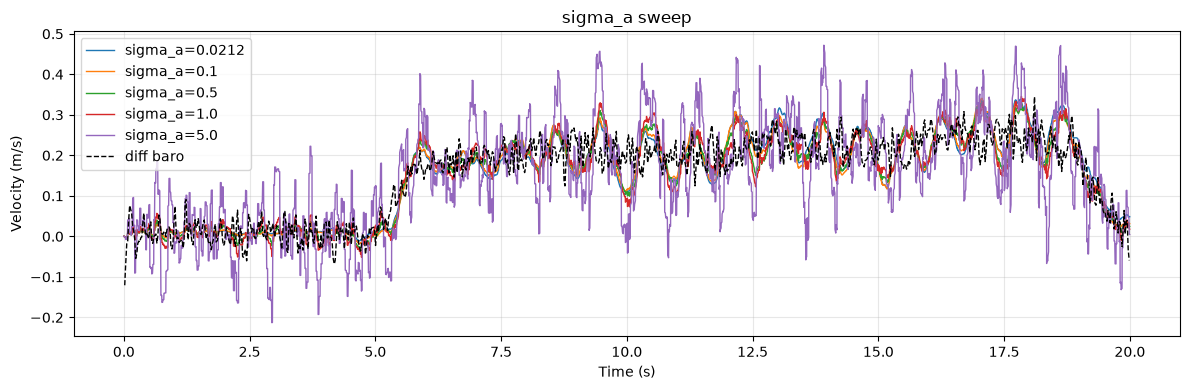

In [11]:
# Try different sigma_a values
sigma_as = [SIGMA_A, 0.1, 0.5, 1.0, 5.0]

# Run a filter for each value
p_traces = []
v_traces = []
for sa in sigma_as:
    # Run filter on sorted events from the recording
    t_kf, p_kf, v_kf = run_kalman_filter(data["events"], sa, SIGMA_Z)
    p_traces.append((t_kf, p_kf, f"sigma_a={sa}"))
    v_traces.append((t_kf, v_kf, f"sigma_a={sa}"))

    # Sample the KF estimated states at the barometer times
    v_kf_at_baro = np.interp(data["t_baro"], t_kf, v_kf)

    # Compute RMS error of velocity estimate vs. reference
    v_err_rms = rms(v_kf_at_baro - data["v_ref"])
    
    # Print stats for this run
    print(f"sigma_a={sa:.4f}, v_err RMS={v_err_rms:.3f} m/s")

# Add reference plots last (so we can see them clearly)
p_traces.append((data["t_baro"], data["p_ref"], "smoothed baro", {"color": "k", "ls": ":", "lw": 2}))
v_traces.append((data["t_baro"], data["v_ref"], "diff baro", {"color": "k", "ls": "--", "lw": 1}))

# Plot position (altitude) and velocity for each recording
utils.plot_traces(p_traces, "Altitude (m)", title=f"sigma_a sweep")
utils.plot_traces(v_traces, "Velocity (m/s)", title=f"sigma_a sweep")

## Evaluation

We run the tuned filter on a couple of recordings that we did not use for tuning.

In [12]:
# Choose the sigma_a with the lowest v_err RMS from the previous section
SIGMA_A_TUNED = 0.5

Duration: 20.0 s
Accel samples: 2490 (124.5 Hz)
Baro samples: 998 (49.9 Hz)
v_err RMS=0.050 m/s


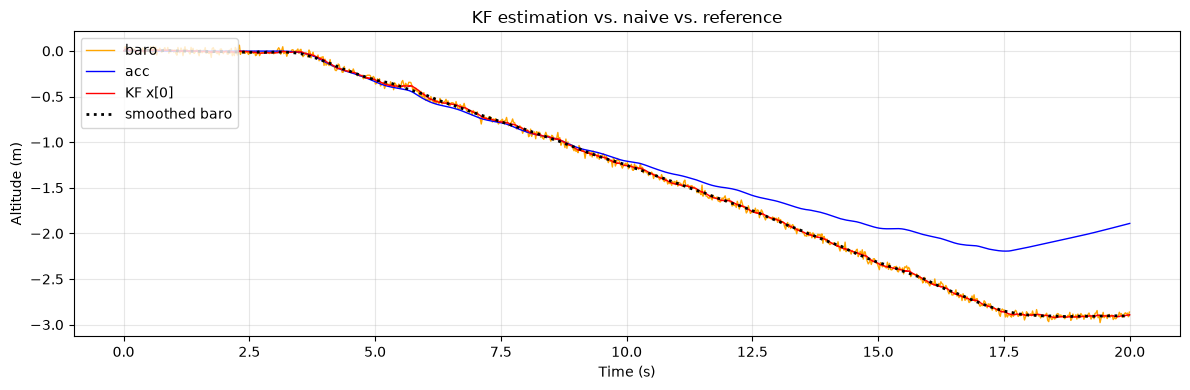

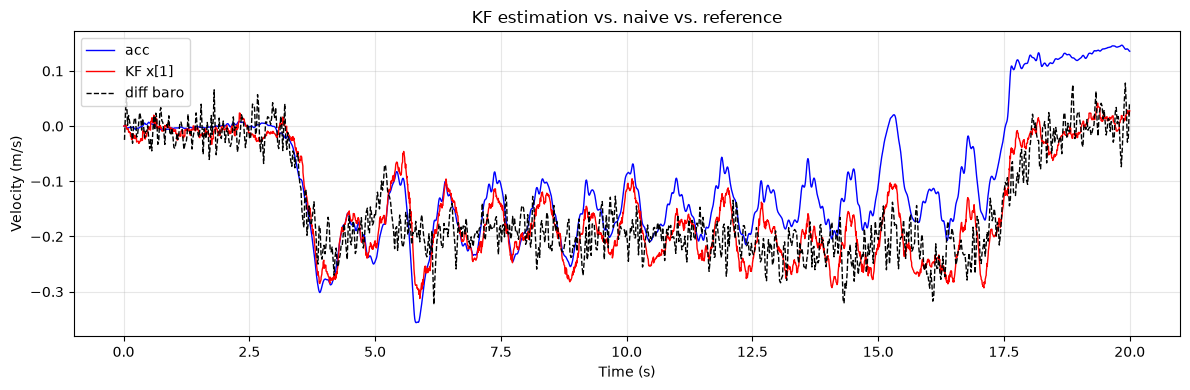

In [13]:
# Evaluate walking down stairs
eval_log(STAIRS_DOWN_PATH, REF_TIME_S, SIGMA_A_TUNED, SIGMA_Z)

Duration: 40.0 s
Accel samples: 4979 (124.5 Hz)
Baro samples: 1997 (49.9 Hz)
v_err RMS=0.050 m/s


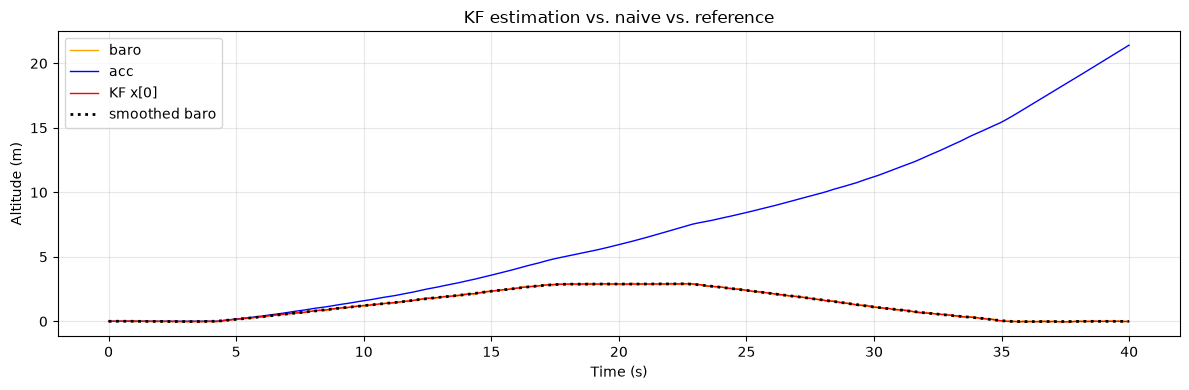

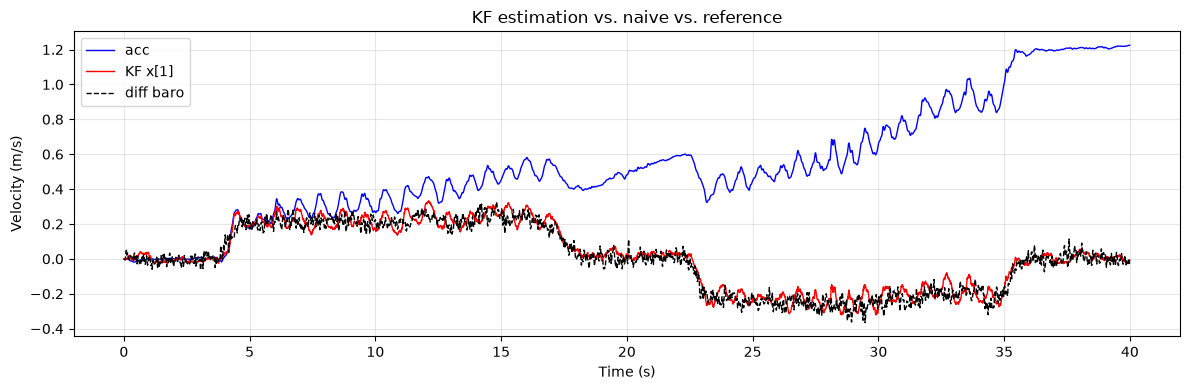

In [14]:
# Evaluate round trip on stairs log
eval_log(STAIRS_ROUND_PATH, REF_TIME_S, SIGMA_A_TUNED, SIGMA_Z)

Duration: 60.0 s
Accel samples: 7470 (124.5 Hz)
Baro samples: 2996 (49.9 Hz)
v_err RMS=0.037 m/s


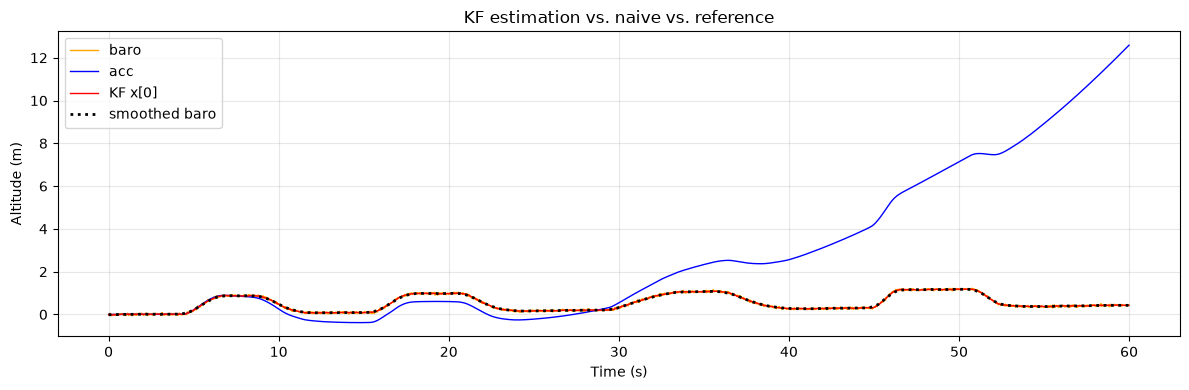

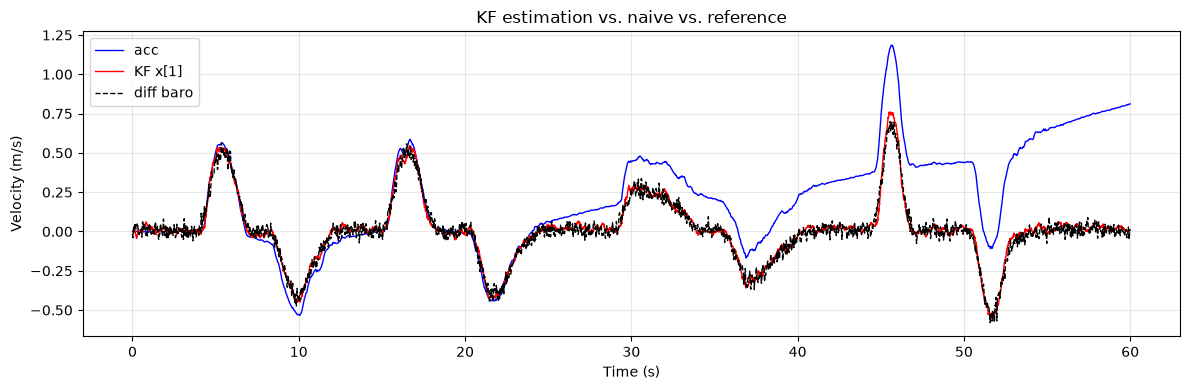

In [15]:
# Evaluate lifting and putting down sensors
eval_log(LIFT_PATH, REF_TIME_S, SIGMA_A_TUNED, SIGMA_Z)

## Takeaways

When properly tuned, the Kalman filter follows the accelerometer in the short term (responsive) and the barometer in the long term (no drift). We get a smooth vertical velocity with no lag. Note that the filter inherits the barometer's long-term errors (e.g. pressure/temperature changes).